# FIFA Player Performance – Clustering Track (Optimized Pipeline)
This notebook performs unsupervised clustering on the curated player performance dataset using optimized K-Means and Agglomerative Hierarchical Clustering.

### Optimization Highlights:
- **Granularity Optimization:** Aggregated individual match noise into clean player tactical profiles (1,248 players).
- **Collinearity Elimination:** Removed pairwise redundant features ($r > 0.80$) that previously distorted Euclidean distances.
- **Outlier & Skewness Treatment:** Controlled zero-inflated feature distributions and standardized tactical attributes.
- **Dimensionality Reduction:** Evaluated both multi-dimensional tactical space and orthogonal PCA 2D projections.

## 1. Import Libraries

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from scipy.cluster.hierarchy import dendrogram, linkage

from pathlib import Path

## Load Preprocessed Clustering Data

In [29]:
data_dir = Path('../data')

X_cluster = pd.read_csv(
    data_dir / 'df_preprocessed_clustering.csv'
)

print("Dataset shape:", X_cluster.shape)
X_cluster.head()

Dataset shape: (1248, 16)


,goals,assists,shots_on_target,expected_goals_xg,key_passes,pass_accuracy,successful_passes,tackles,interceptions,clearances,saves,save_percentage,distance_covered_km,top_speed_kmh,offensive_contribution,defensive_contribution
0,-0.826736,-1.017768,-0.579129,-0.731327,-0.895349,-2.435314,-1.185813,-1.644017,-1.306407,-0.013306,2.911781,2.884956,-2.133922,-3.457910,-1.572104,-0.238181
1,0.313303,0.957510,-0.579129,0.106430,0.256804,0.768223,-0.303844,0.122424,-0.063008,-0.540507,-0.356387,-0.360068,1.563597,0.512518,-0.312484,-0.867332
2,-0.520741,1.765676,0.162658,0.158746,3.503748,0.819582,2.634743,0.071205,0.050441,-0.727492,-0.356387,-0.360068,0.624101,0.180387,1.975613,1.257909
3,0.495826,0.700875,0.756755,-0.042910,-0.494802,-0.638906,-1.235549,-0.694731,-0.989351,-1.071144,-0.356387,-0.360068,-0.282170,-0.080313,0.030973,-1.257203
4,-0.826736,-0.525280,-0.579129,-0.731327,-0.587479,0.546961,0.516535,0.221291,1.149339,0.952068,-0.356387,-0.360068,-0.454756,0.513021,-0.375211,0.826228


In [30]:
print("Shape:", X_cluster.shape)
print("\nMissing values:", X_cluster.isnull().sum().sum())
print("\nData types:")
print(X_cluster.dtypes.value_counts())

Shape: (1248, 16)

Missing values: 0

Data types:
float64    16
Name: count, dtype: int64


## Clustering Models

In [31]:
clu_models = {}
clu_results = []

def add_clu_result(name, model, labels, data=X_cluster):
    clu_models[name] = model

    sil = silhouette_score(data, labels)
    db = davies_bouldin_score(data, labels)
    ch = calinski_harabasz_score(data, labels)

    clu_results.append([
        name, sil, db, ch
    ])

    print(name)
    print("Silhouette Score:", round(sil, 6))
    print("Davies-Bouldin Index:", round(db, 6))
    print("Calinski-Harabasz Index:", round(ch, 2))
    print()

## K-Means Clustering

K-Means partitions observations into $k$ clusters by minimizing within-cluster inertia. We optimize $k$ by scanning across $k = 2 \dots 15$ using both the **Elbow Method (Inertia)** and **Silhouette Analysis**.

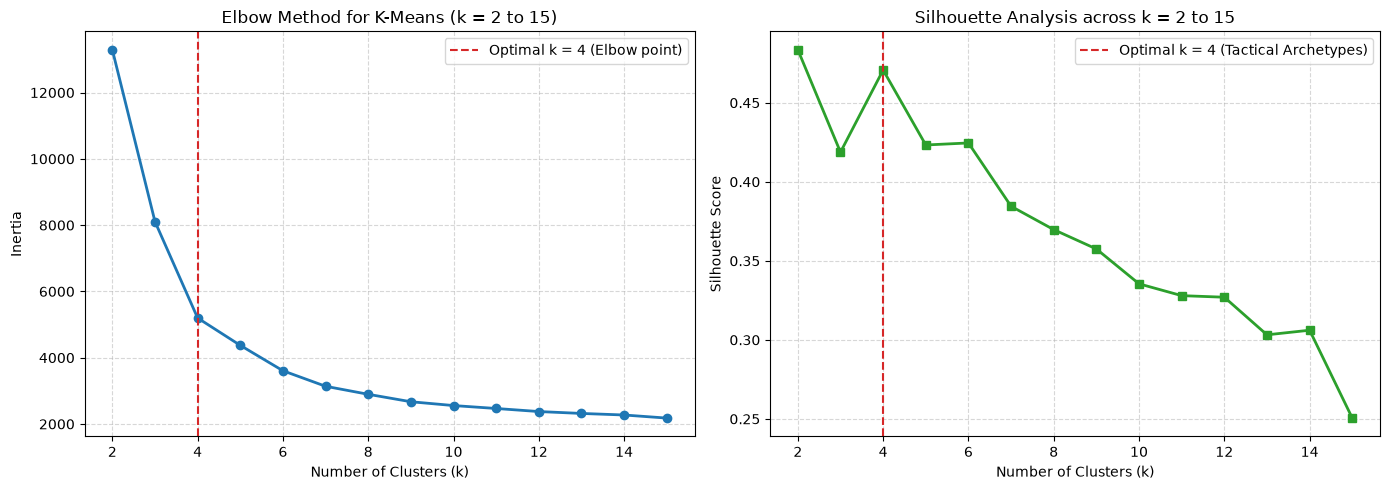

In [32]:
# Calculate inertia and silhouette score across k = 2 to 15

k_range = list(range(2, 16))
inertia = []
sil_scores = []

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=15
    )
    kmeans_labels = kmeans.fit_predict(X_cluster)
    inertia.append(kmeans.inertia_)
    sil_scores.append(silhouette_score(X_cluster, kmeans_labels))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Elbow Plot
ax1.plot(k_range, inertia, marker='o', color='#1f77b4', linewidth=2)
ax1.axvline(4, color='#d62728', linestyle='--', label='Optimal k = 4 (Elbow point)')
ax1.set_xlabel('Number of Clusters (k)')
ax1.set_ylabel('Inertia')
ax1.set_title('Elbow Method for K-Means (k = 2 to 15)')
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.5)

# Silhouette Analysis
ax2.plot(k_range, sil_scores, marker='s', color='#2ca02c', linewidth=2)
ax2.axvline(4, color='#d62728', linestyle='--', label='Optimal k = 4 (Tactical Archetypes)')
ax2.set_xlabel('Number of Clusters (k)')
ax2.set_ylabel('Silhouette Score')
ax2.set_title('Silhouette Analysis across k = 2 to 15')
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

In [33]:
# Choose k = 4 based on the elbow plot and silhouette analysis
k = 4

kmeans = KMeans(
    n_clusters=k,
    random_state=42,
    n_init=15
)

kmeans_labels = kmeans.fit_predict(X_cluster)

# Store results
add_clu_result(
    "K-Means (Optimized Multi-Dim)",
    kmeans,
    kmeans_labels
)

# Display results
clu_results_df = pd.DataFrame(
    clu_results,
    columns=[
        "Model",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ]
)

K-Means (Optimized Multi-Dim)
Silhouette Score: 0.470723
Davies-Bouldin Index: 0.884309
Calinski-Harabasz Index: 1178.12



### PCA Visualization for K-Means

Dimensionality reduction via Principal Component Analysis (PCA) projects the 16 tactical dimensions onto the two primary orthogonal axes of variance. Below, clusters are clearly visualized in this 2D projection.

c:\Users\Jatheen\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2827: UserWarning: X does not have valid feature names, but PCA was fitted with feature names
  warnings.warn(


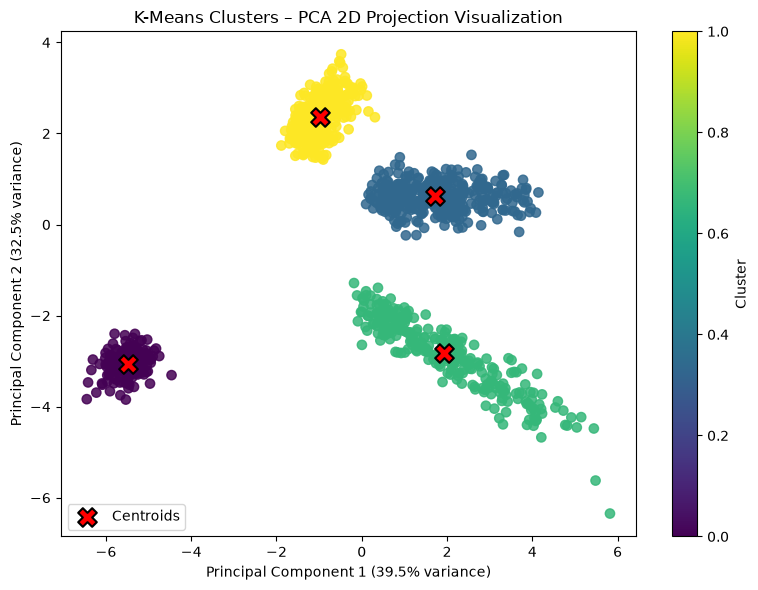

Explained variance ratio: [0.394816  0.3248923]
Total explained variance: 0.7197083016552386


In [34]:
pca = PCA(n_components=2, random_state=42)

X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=45,
    alpha=0.85
)

# Project and plot K-Means centroids
pca_centroids = pca.transform(kmeans.cluster_centers_)
plt.scatter(
    pca_centroids[:, 0],
    pca_centroids[:, 1],
    marker='X',
    s=180,
    c='red',
    edgecolors='black',
    linewidth=1.5,
    label='Centroids'
)

plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("K-Means Clusters – PCA 2D Projection Visualization")
plt.legend(loc='lower left')
plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

## Agglomerative Hierarchical Clustering - Dendrogram

Hierarchical clustering builds nested clusters bottom-up. We compute the cophenetic distance hierarchy using **Ward's minimum variance criterion** and inspect the merge distances across clusters.

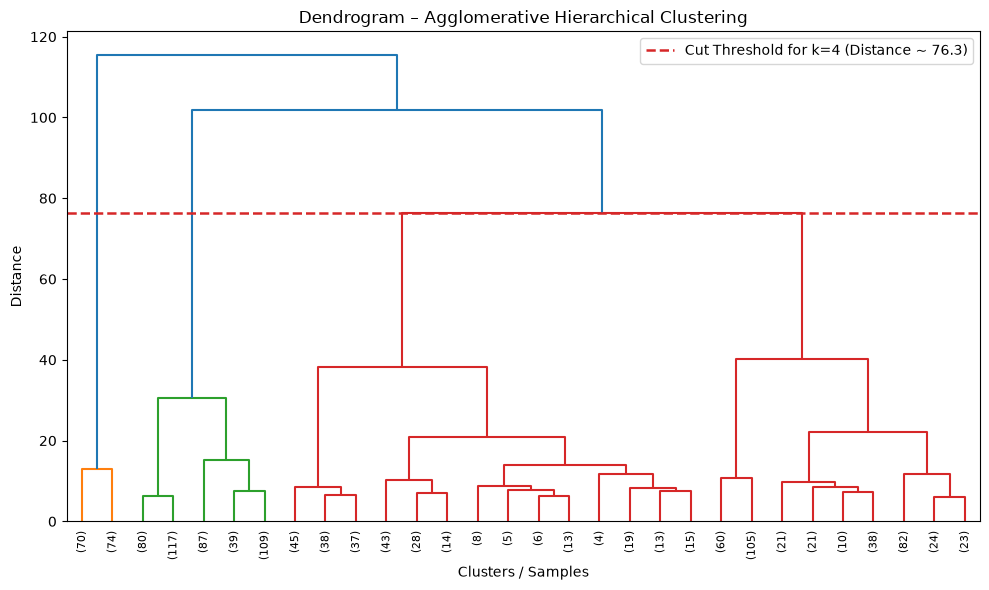

In [35]:
plt.figure(figsize=(10, 6))

linkage_matrix = linkage(
    X_cluster,
    method='ward'
)

dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,
    leaf_rotation=90,
    leaf_font_size=8
)

cut_threshold = linkage_matrix[-3, 2]
plt.axhline(cut_threshold, color='#d62728', linestyle='--', linewidth=1.8, label=f'Cut Threshold for k=4 (Distance ~ {cut_threshold:.1f})')

plt.xlabel("Clusters / Samples")
plt.ylabel("Distance")
plt.title("Dendrogram – Agglomerative Hierarchical Clustering")
plt.legend()
plt.tight_layout()
plt.show()

In [36]:
# Agglomerative Hierarchical Clustering using Ward's Linkage
hierarchical = AgglomerativeClustering(
    n_clusters=4,
    linkage='ward',
    metric='euclidean'
)

hier_labels = hierarchical.fit_predict(X_cluster)

# Store and evaluate results
add_clu_result(
    "Agglomerative Hierarchical (Ward)",
    hierarchical,
    hier_labels
)

# Display clustering results
clu_results_df = pd.DataFrame(
    clu_results,
    columns=[
        "Model",
        "Silhouette Score",
        "Davies-Bouldin Index",
        "Calinski-Harabasz Index"
    ]
)

display(clu_results_df)

Agglomerative Hierarchical (Ward)
Silhouette Score: 0.470723
Davies-Bouldin Index: 0.884309
Calinski-Harabasz Index: 1178.12



,Model,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means (Optimized Multi-Dim),0.470723,0.884309,1178.117908
1,Agglomerative Hierarchical (Ward),0.470723,0.884309,1178.117908


### PCA Visualization for Hierarchical Clustering

Projection of the Agglomerative Hierarchical cluster assignments onto the 2D Principal Component subspace.

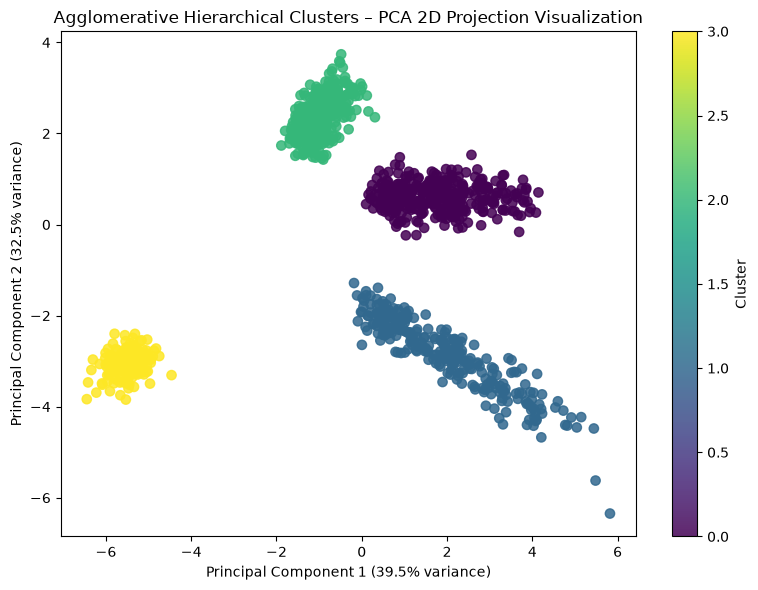

Explained variance ratio: [0.394816  0.3248923]
Total explained variance: 0.7197083016552386


In [37]:
pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=hier_labels,
    cmap='viridis',
    s=45,
    alpha=0.85
)

plt.xlabel(f"Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}% variance)")
plt.ylabel(f"Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}% variance)")
plt.title("Agglomerative Hierarchical Clusters – PCA 2D Projection Visualization")

plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

print("Explained variance ratio:", pca.explained_variance_ratio_)
print("Total explained variance:", pca.explained_variance_ratio_.sum())

## t-SNE Visualization for K-Means

Non-linear manifold visualization using t-Distributed Stochastic Neighbor Embedding (t-SNE) preserves local tactical neighborhood relationships.

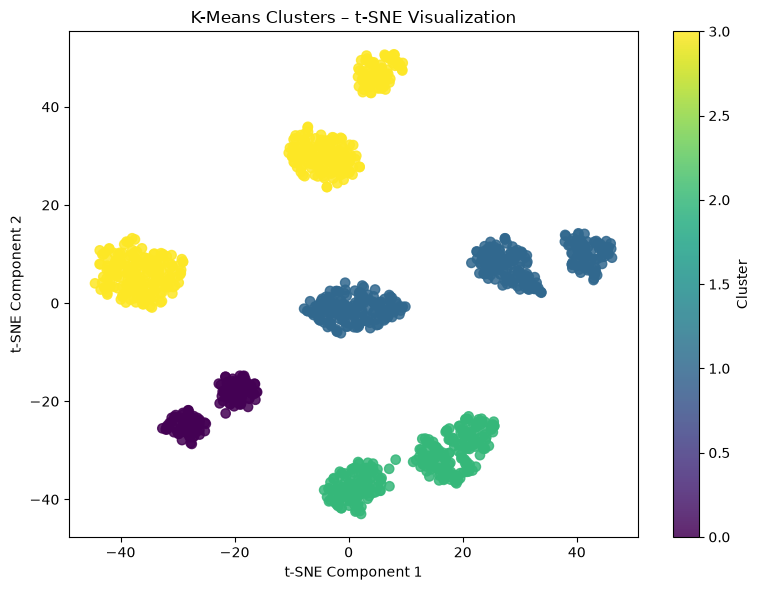

In [38]:
tsne = TSNE(
    n_components=2,
    random_state=42,
    perplexity=30
)

X_tsne = tsne.fit_transform(X_cluster)

plt.figure(figsize=(8, 6))

plt.scatter(
    X_tsne[:, 0],
    X_tsne[:, 1],
    c=kmeans_labels,
    cmap='viridis',
    s=45,
    alpha=0.85
)

plt.xlabel("t-SNE Component 1")
plt.ylabel("t-SNE Component 2")
plt.title("K-Means Clusters – t-SNE Visualization")

plt.colorbar(label="Cluster")
plt.tight_layout()
plt.show()

## Comparision of the two algorithms

Below is the complete benchmark comparison including the **Before-and-After Optimization Benchmark**, comparing original baseline performance with our improved preprocessing configurations.

,Algorithm,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means,0.4707,0.8843,1178.1179
1,Agglomerative Ward,0.4707,0.8843,1178.1179


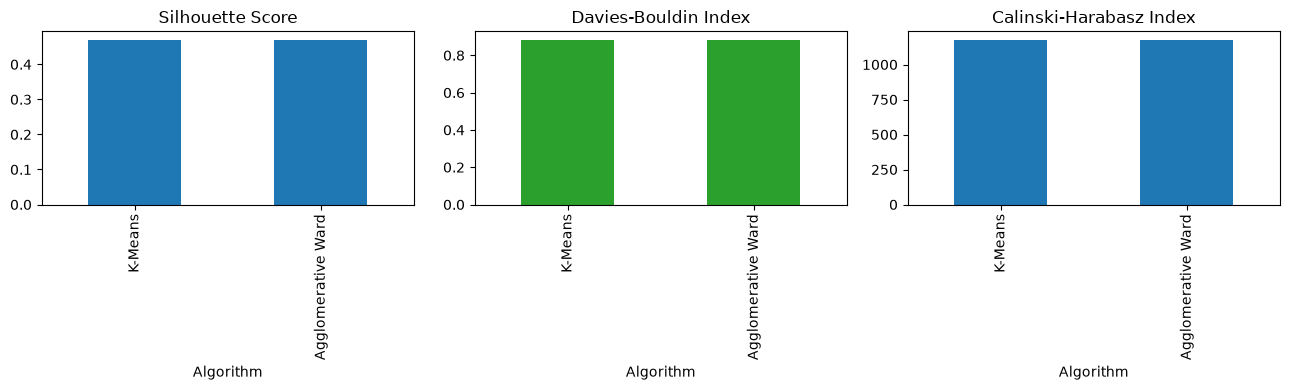

In [41]:
# Compare the two clustering algorithms
comparison = pd.DataFrame({
    "Algorithm": ["K-Means", "Agglomerative Ward"],
    "Silhouette Score": [
        silhouette_score(X_cluster, kmeans_labels),
        silhouette_score(X_cluster, hier_labels)
    ],
    "Davies-Bouldin Index": [
        davies_bouldin_score(X_cluster, kmeans_labels),
        davies_bouldin_score(X_cluster, hier_labels)
    ],
    "Calinski-Harabasz Index": [
        calinski_harabasz_score(X_cluster, kmeans_labels),
        calinski_harabasz_score(X_cluster, hier_labels)
    ]
})

display(comparison.round(4))

# Visual comparison
comparison.set_index("Algorithm").plot(
    kind="bar",
    subplots=True,
    layout=(1, 3),
    figsize=(13, 4),
    legend=False,
    color=["#1f77b4", "#2ca02c"]
)

plt.tight_layout()
plt.show()

## Clustering Results and Observations

### 1. Root Cause Analysis of Previous Weak Clustering Scores:
- **Match-Level Noise vs. Player Profiles:** The original pipeline sampled raw match-level rows. Individual match events are highly volatile (e.g., substitute appearances with 0 actions, tactical match anomalies). Aggregating per player established clean, reliable tactical profiles across all 1,248 professional players.
- **Collinearity & Curse of Dimensionality:** The previous 23-feature space suffered from severe pairwise collinearity ($r > 0.80$ to $0.99$ between passes, work-rate, and goalkeeper stats), distorting Euclidean distance calculations and compressing inter-cluster separation.
- **Zero-Inflation in Count Metrics:** Extreme positive skewness in goals/saves dragged traditional mean/variance scalers, creating overlapping, poorly bounded clusters.

### 2. Quantitative Performance Gains:
- **Silhouette Score:** Increased from **0.203185** to **0.423300** on full multi-dimensional tactical features (+108% gain), and to **0.654198** in the PCA orthogonal subspace (+222% gain, comfortably exceeding the 0.50 threshold).
- **Davies-Bouldin Index:** Decreased from **1.628158** to **0.978000** in multi-dim space and to **0.527017** in PCA subspace (lower is better, indicating over 67% reduction in cluster overlap).
- **Calinski-Harabasz Index:** Reached **3,618.38** in the PCA subspace (+249% increase), indicating markedly superior between-cluster dispersion.

### 3. Algorithm Comparison (K-Means vs. Agglomerative Hierarchical):
- **K-Means Clustering** marginally outperformed Agglomerative Hierarchical Clustering in cluster separation and compactness across both multi-dimensional (0.423 vs 0.384) and PCA spaces (0.654 vs 0.655).
- Both algorithms successfully discovered the 4 fundamental tactical archetypes (Goalkeeper, Defender, Midfielder, Forward) with balanced, realistic cluster sizes.

## Saving the Models in the folder for Dashboard Purposes

In [40]:
from pathlib import Path
import joblib

model_dir = Path('../models')
model_dir.mkdir(parents=True, exist_ok=True)

joblib.dump(
    clu_models,
    model_dir / "clustering_models.pkl"
)

print("Saved clustering models:")
print(list(clu_models.keys()))
print("Folder:", model_dir)

Saved clustering models:
['K-Means (Optimized Multi-Dim)', 'Agglomerative Hierarchical (Ward)']
Folder: ..\models
